In [1]:
# multi class classification of FGL sources using tree categories
import numpy as np
import pandas as pd
from matplotlib import pyplot
#from scipy.stats import binom
import random
from astropy.io import fits
print(np.__version__)


from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve
from sklearn.calibration import calibration_curve
import sklearn
print(sklearn.__version__)

import time
import os
import sys
if '../lib/' not in sys.path:
    sys.path.append('../lib/')
import dio3
import multi_fgl_utils as util
import plot_util as putil

1.26.4
1.4.1.post1


In [2]:
if 1:
    import importlib
    importlib.reload(util);
    importlib.reload(putil);


In [3]:
def calibration_curve_loc(y_true, y_score, n_bins=10, sample_weight=None):
    bins = np.linspace(0., 1., n_bins + 1)
    if sample_weight is None:
        weight = np.ones_like(y_true, dtype=float)
    else:
        weight = sample_weight
    ptrue = np.histogram(y_score, bins=bins, weights=y_true*weight)[0]
    pscore = np.histogram(y_score, bins=bins, weights=y_score*weight)[0]
    norm = np.histogram(y_score, bins=bins, weights=weight)[0]
    mask = norm > 0
    ptrue[mask] = ptrue[mask] / norm[mask]
    pscore[mask] = pscore[mask] / norm[mask]
    if any(pscore[mask][1:] - pscore[mask][:-1] < 0):
        print('strange pscore')
        print(pscore)
    return ptrue, pscore
    

In [4]:
make_thres_bins = util.make_thres_bins

In [39]:
script_fn = 'fermi_multiclass/notebooks/multi_class_fgl.ipynb'
fig_meta = {'Author': 'Dmitry Malyshev', 'Subject': script_fn}


# select the catalog and the case
cat_name = '4FGL-DR4' # '4FGL-DR3'
if cat_name == '4FGL-DR4':
    baseline_case = '4FGL-DR4_2class_RF' # '4FGL-DR4_GMM_RF', '4FGL-DR4_2class_RF'
    #baseline_case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp'
    #baseline_fn = '%s_baseline.yaml' % baseline_case
    #cases_fn = '%s_cases.yaml' % baseline_case
    #case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp' # '4FGL-DR4_GMM_RF_no_prune'
    #case = '4FGL-DR4_2class_RF'
    case = '4FGL-DR4_2class_pulsars_AGNs' # '4FGL-DR4_2class_pulsars_AGNs', '4FGL-DR4_2class_pulsars'
    #case = '4FGL-DR4_GMM_RF'
    #case = '4FGL-DR4_GMM_NN_wt'
if cat_name == '4FGL-DR3':
    baseline_case = '4FGL-DR3_GMM_RF_no_coord_no_bcu_spp'
    case = '4FGL-DR3_GMM_RF_no_coord_no_bcu_spp'
    #case = '4FGL-DR3_GMM_RF_no_coord_no_bcu_spp_nmin50'
    #baseline_case = '4FGL-DR3_3class_RF'
    #case = '4FGL-DR3_3class_RF'
    #case = '4FGL-DR3_3class_NN'

baseline = (case == baseline_case)
root_folder = '../'
config_folder = root_folder + 'config/'

# generic inputs
cdict = util.get_config_dict(#cat_name=cat_name, 
                             baseline_case=baseline_case, 
                             #baseline_fn=baseline_fn,
                             #cases_fn=cases_fn,
                             case=case, 
                             folder=config_folder)

cdict['root_folder'] = root_folder
folder_in = cdict['root_folder'] + cdict.get('folder_in', 'data_in/')
folder_out = cdict['root_folder'] + cdict.get('folder_out', 'data_out/')
folder = folder_out
Eind = int(cdict.get('Eind', 1000))
class_name = cdict.get('class_name', 'CLASS1')

assoc_sources = cdict.get('assoc_sources', 'all_assoc')
sep_model = cdict.get('sep_model', 'GMM')
#sep_model = 'RF' # 'GMM', 'RF'
nmin = cdict.get('nmin')
if nmin is not None: 
    nmin = int(nmin)
max_depth = int(cdict.get('max_depth', 5))
feature_mode = cdict.get('features', 'all_features')

alg = cdict.get('class_alg', 'RF')
train_weighting = cdict.get('train_weighting')
test_weighting = cdict.get('test_weighting')
weighted = (train_weighting is not None) or (test_weighting is not None)
#oversample_factor = 1 # used for 'resampled' training and testing
max_sample = int(cdict.get('max_sample', 7))
test_frac = float(cdict.get('test_frac', 0.3))
train_frac = 1. - test_frac
nav = int(cdict.get('nav', 10))
test_gal_plane = False
if test_gal_plane:
    cdict['test_gal_plane'] = 1
    glon_max_test = 30
    glat_max_test = 30
    cdict['glon_max_test'] = glon_max_test
    cdict['glat_max_test'] = glat_max_test
    sin_glon_max = np.sin(np.deg2rad(glon_max_test))
    sin_glat_max = np.sin(np.deg2rad(glat_max_test))
else:
    cdict['test_gal_plane'] = 0

tree_alg = cdict.get('sep_model', 'GMM')
#tree_alg = 'RF' # 'stat', 'GMM', 'RF', '4class', '2class', 'RF_aakash'


# input data
tree_cat_fn = util.get_tree_cat_fn(cdict)
tree_cat_dict = dio3.loaddict(tree_cat_fn)
if util.exist_internal(tree_cat_dict):
    util.remove_internal(tree_cat_dict)
cat_tree = list(tree_cat_dict.keys())

xdf_fn = util.get_xdf_fn(cdict)
xdf = pd.read_csv(xdf_fn, index_col=0)
ns = len(xdf)

all_features = [name for name in xdf.columns if name.find('CLASS') == -1]
if feature_mode == 'all_features':
    features = all_features
elif feature_mode == 'no_coord_features':
    features = [feat for feat in all_features if feat.find('GL') == -1]


nsrc_dict = util.get_nsrc_dict(xdf, class_column=class_name, classes='associated')
if assoc_sources == 'no_bcu_spp':
    excl_cls = ['bcu', 'spp', 'unas', 'unk']
    assoc_classes = [cl for cl in list(set(xdf[class_name])) if cl not in excl_cls]
else:
    assoc_classes = list(nsrc_dict.keys())


# algorithm description string
pars_dict = util.pars_dict
pars_dict['NN']['nfeatures'] = len(features)
pars_dict['NN']['epochs'] = cdict.get('epochs', 500)
alg_descr = util.get_alg_descr(cdict, pars_dict=pars_dict)


# specific inputs and definitions
if tree_alg.find('2class') > -1:
    title_dict = {'00': 'Extragalactic', '01': 'Galactic'}

purpose = 'multi-paper' # 'DFG', 'multi-paper', 'presentation', 'test'

level0 = 0
max_level = util.max_node_length(cat_tree) - 1
class1 = '01'


#assoc_classes = []
#for cls in tree_cat_dict.values():
#    assoc_classes.extend(cls)
#nsrc_dict = {cl:np.sum(xdf[class_name] == cl) for cl in assoc_classes}

alg_dict = {'RF': 'Random Forest',
           'NN': 'Neural Network'}

if baseline and False:
    title_str = ''
elif tree_alg.find('2class') > -1:
    title_str = '2-class + %s classif' % (alg)
elif tree_alg.find('3class') > -1:
    title_str = '3-class + %s classif' % (alg)
elif tree_alg == '4class':
    title_str = '4-class + %s classif' % (alg)    
elif train_weighting or test_weighting:
    title_str = '%s' % (alg)
else:
    title_str = '%s (nmin=%i) + %s classif' % (tree_alg, nmin, alg)

if alg.startswith('NN'):
    title_str += ' (layers'
    for ls in pars_dict[alg]['hidden_layer_sizes']:
        title_str += ' %i,' % ls
    title_str = title_str[:-1] + ')'

if train_weighting or test_weighting:
    if train_weighting and test_weighting:
        title_str += ', weighted training and testing'
    elif test_weighting:
        title_str += ', weighted testing'
        

if test_gal_plane:
    title_str += ', test |lon| < %i, |lat| < %i around GC' % (glon_max_test, glat_max_test)

#putil.setup_figure_pars()
single_plot_pars = {}
all_plots_pars = {'bottom':0.1, 'left':0.08, 'right':0.98, 'axes.titlesize':18,
                 'font.size':13}
if nmin == 15:
    all_plots_pars['left'] = 0.05
    all_plots_pars['font.size'] = 14
if tree_alg == '4class':
    all_plots_pars = {'bottom':0.12, 'left':0.12, 'right':0.98, 'axes.titlesize':18}
elif tree_alg.find('2class') > -1:
    all_plots_pars = {'bottom':0.15, 'left':0.15, 'right':0.98, 'axes.titlesize':18}
colors = pyplot.rcParams['axes.prop_cycle'].by_key()['color']

save_plots = 0
save_png = 0
copy2tex = 0
save_results = 1
if purpose == 'multi-paper':
    plots_folder = '../plots/mclass/%s/' % alg_descr
    #save_plots = 1
elif purpose == 'DFG':
    plots_folder = '../plots/dfg/%s/' % alg_descr
    #save_plots = 1
    
if not os.path.isdir(plots_folder):
    os.mkdir(plots_folder)

split_alg_descr = '%s' % tree_alg
if tree_alg == 'GMM' or tree_alg == 'RF':
    split_alg_descr += '_nmin%s' % (nmin)
viz_plots_folder = '../plots/mclass/viz_split_%s/' % split_alg_descr
if not os.path.isdir(viz_plots_folder):
    os.mkdir(viz_plots_folder)

paper_folder = '/Users/Dmitry/Work/Fermi/fermi_multiclass_papers/3_cov_shift_paper\
/cov_shift_paper_main/'

results_folder = '../data_out/results_%s/' % alg_descr
if not os.path.isdir(results_folder):
    os.mkdir(results_folder)

nsrc_fn = '../data_out/nsrc_dict_%s.yaml' % cat_name
if not os.path.isfile(nsrc_fn):
    dio3.savedict(nsrc_dict, nsrc_fn)
else:
    print('Number of sources file exists:')
    print(nsrc_fn)
    

print(alg_descr)
print(xdf_fn)
print(cdict)
print(tree_cat_dict)

Number of sources file exists:
../data_out/nsrc_dict_4FGL-DR4.yaml
4FGL-DR4_no_bcu_spp_no_coord_features_2class_pulsars_AGNs_RF_depth15
../data_out/xdf_4FGL-DR4_Eind1000MeV.csv
{'cat_name': '4FGL-DR4', 'Eind': 1000, 'add_plec_pars': 0, 'max_sample': 10, 'nGMM_w': 12, 'sep_model': '2class_pulsars_AGNs', 'features': 'no_coord_features', 'root_folder': '../', 'folder_out': 'data_out/', 'folder_in': 'data_in/', 'class_alg': 'RF', 'assoc_sources': 'no_bcu_spp', 'test_gal_plane': 0}
{'00': ['fsrq', 'bll'], '01': ['psr', 'msp', 'glc']}


In [40]:
util.get_alg_descr(cdict, pars_dict=pars_dict), results_folder

('4FGL-DR4_no_bcu_spp_no_coord_features_2class_pulsars_AGNs_RF_depth15',
 '../data_out/results_4FGL-DR4_no_bcu_spp_no_coord_features_2class_pulsars_AGNs_RF_depth15/')

In [41]:
cls_mask = util.get_cl_mask(assoc_classes, xdf, cname=class_name)
print('N assoc:', np.sum(cls_mask))
print('N unas:', np.sum(~cls_mask))
print('Total:', len(xdf))
print(1637 + 1557)
print((1637 + 1557)/np.sum(cls_mask))

N assoc: 2866
N unas: 4325
Total: 7191
3194
1.1144452198185624


In [42]:
if weighted:
    weights_fn = util.get_weights_fn(cdict)
    weights_df = pd.read_csv(weights_fn, index_col=0)
    sample_ratio = util.get_sample_ratio(weights_df['unas_pdf'], weights_df['assoc_pdf'], binary=False, 
                                         max_sample=max_sample)
    print(weights_fn)

In [43]:
#sample_ratio

In [44]:
for key, cls in tree_cat_dict.items():
    nsrc = np.sum([nsrc_dict[cl] for cl in cls])
    #print(key)
    st = 'Group %s: ' % key[1:]
    for cl in cls:
        st += '%s, ' % cl
    st = st[:-2] + ' (%i sources);' % nsrc
    st += r' \\'
    print(st)

Group 0: fsrq, bll (2309 sources); \\
Group 1: psr, msp, glc (354 sources); \\


In [45]:
cat_tree

['00', '01']

In [46]:
horiz_trees = util.get_horiz_trees(cat_tree, mode='add_0')
max_level = np.minimum(max_level, len(horiz_trees))

In [47]:
cat_tree, horiz_trees

(['00', '01'], [['00', '01']])

In [48]:
run_random_cut = False
if run_random_cut:
    # get a random cut
    cat_forest = util.get_forest(max_depth=None, max_tree=cat_tree)
    print(len(cat_forest))
    #ind = np.random.randint(len(cat_forest))
    ind = 50
    subtree = cat_forest[ind]
    cut_subtree = util.sub_tree2tree_cat_dict(subtree, cat_tree, tree_cat_dict)

In [49]:
if run_random_cut:
    print('Max tree')
    for key, cls in tree_cat_dict.items():
        nsrc = np.sum([nsrc_dict[cl] for cl in cls])
        print(key, cls, nsrc)
    print()
    print('Subtree')
    for key, cls in cut_subtree.items():
        nsrc = np.sum([nsrc_dict[cl] for cl in cls])
        print(key, cls, nsrc)


In [50]:
if run_random_cut:
    ys = np.zeros(ns, dtype='<U%i' % (max_depth + 1))
    clf_mask = np.zeros(ns, dtype=bool)
    cls_masks_all = []
    for key, cls in cut_subtree.items():
        cls_mask = util.get_cl_mask(cls, xdf, cname=class_name)
        cls_masks_all.append(cls_mask)
        ys[cls_mask] = key
        clf_mask[cls_mask] = True
    cls_masks_all = np.array(cls_masks_all)

    X = xdf[features][clf_mask]
    y = ys[clf_mask]


In [51]:
run_random_cut

False

In [52]:
if run_random_cut:
    nav = 10
    keys = cut_subtree.keys()
    prob_prec_test = np.zeros((nav, len(keys)))
    prob_recall_test = np.zeros((nav, len(keys)))
    nsrc_test = np.zeros((nav, len(keys)))
    for j in range(nav):
        clf = util.get_classifier(alg, pars_dict[alg])
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.3, random_state=j)
        clf.fit(X_train, y_train)

        pred_test = clf.predict_proba(X_test).T
        inds = [list(clf.classes_).index(key) for key in keys]
        pred_test = np.array([pred_test[ind] for ind in inds])

        cls_masks_test = []
        for key in keys:
            cls_mask = (y_test == key)
            cls_masks_test.append(cls_mask)
        cls_masks_test = np.array(cls_masks_test, dtype=int)

        true_pred_test = pred_test * cls_masks_test
        prob_prec_test[j] = np.sum(true_pred_test, axis=1) / np.sum(pred_test, axis=1)
        prob_recall_test[j] = np.sum(true_pred_test, axis=1) / np.sum(cls_masks_test, axis=1)
        nsrc_test[j] = np.sum(cls_masks_test, axis=1)


In [53]:
if run_random_cut:
    for i, key in enumerate(keys):
        print(cut_subtree[key])
        print('prec = %.3f +- %.3f' % (np.mean(prob_prec_test[:, i]), np.std(prob_prec_test[:, i])))
        print('recall = %.3f +- %.3f' % (np.mean(prob_recall_test[:, i]), np.std(prob_recall_test[:, i])))
        print('nsrc_test = %.3f +- %.3f' % (np.mean(nsrc_test[:, i]), np.std(nsrc_test[:, i])))


# Parent accuracy consistency

In [54]:
if 0:
    horiz_trees = util.get_horiz_trees(cat_tree)
    #print(horiz_trees)
elif 0:
    subtree = ['0']
    horiz_trees = []
    while util.max_node_length(subtree) < util.max_node_length(cat_tree):
        subtree = util.get_children(subtree, cat_tree)
        horiz_trees.append(subtree)
    #print(horiz_trees)

In [55]:


#pred_dict = {}
pred_dict_all = [{} for j in range(nav)]
rel_dict = [{} for j in range(nav)]
pgrid = np.arange(0, 1.000001, 0.1)

parents = horiz_trees[level0]

pred_test = {}
clfs_dict = {}
auc_scan = {}
if test_gal_plane:
    gal_plane_nsrc_dict = {}
for level, subtree in enumerate(horiz_trees[level0:max_level]):
    print('level', level)
    if test_gal_plane:
        gal_plane_nsrc_dict[level] = {}
    cut_subtree = util.sub_tree2tree_cat_dict(subtree, cat_tree, tree_cat_dict,
                                             include_parents=True)
    nodes = subtree

    ys = np.zeros(ns, dtype='<U%i' % (max_depth + 1))
    #if level == level0:
    #    ys_true = ys
    clf_mask = np.zeros(ns, dtype=bool)
    #cls_masks_all = []
    for key, cls in cut_subtree.items():
        cls_mask = util.get_cl_mask(cls, xdf, cname=class_name)
        #cls_masks_all.append(cls_mask)
        ys[cls_mask] = key
        clf_mask[cls_mask] = True
    #cls_masks_all = np.array(cls_masks_all)
    
    X = xdf[features][clf_mask]
    y = ys[clf_mask]
    
    auc_scan[level] = 0.
    for j in range(nav):
        if alg.startswith('NN'):
            print(j)
            t0 = time.time()
        
        sample_ratio_train = None
        pred_dict_all[j]['test_weights'] = None
        
        if weighted or test_gal_plane:
            clf_inds = np.arange(len(xdf))[clf_mask]
            #clf_inds = list(np.random.permutation(clf_inds).astype(int))
            #ntrain = int((1. - test_frac) * sum(clf_mask))
            #train_mask = np.zeros(len(xdf), dtype=bool)
            #train_mask[clf_inds[:ntrain]] = True
            #test_mask = np.zeros(len(xdf), dtype=bool)
            #test_mask[clf_inds[ntrain:]] = True
            
            #ainds = np.arange(len(xdf))[clf_mask] # replace with clf_mask for a subset of assoc sources
            rstate = np.random.RandomState(seed=j)
            if test_gal_plane:
                gal_mask = np.abs(xdf['sin(GLAT)']) < sin_glat_max
                gal_mask &= np.abs(xdf['sin(GLON)']) < sin_glon_max
                test_inds = [i for i in clf_inds if gal_mask.iloc[i]]
            else:
                test_inds = rstate.choice(clf_inds, size=int(len(clf_inds) * test_frac), replace=False, p=None)
            train_inds = [i for i in clf_inds if i not in test_inds]
            
            if test_gal_plane:
                test_inds = rstate.choice(test_inds, size=int(len(test_inds) * train_frac), 
                                          replace=False, p=None)
                train_inds = rstate.choice(train_inds, size=int(len(train_inds) * train_frac), 
                                          replace=False, p=None)
            
            #if alg == 'RF':
            if train_weighting == 'weighted':
                # add weights to training samples
                sample_ratio_train = sample_ratio.iloc[train_inds]
            elif train_weighting == 'resampled':
                # oversample training indices using weights 
                ntr_samples = oversample_factor * len(train_inds)
                train_inds = random.choices(train_inds, weights=sample_ratio[train_inds], k=ntr_samples)
                    
            if test_weighting == 'weighted':
                # add weights to testing samples
                pred_dict_all[j]['test_weights'] = sample_ratio.iloc[test_inds]
                if j == 0 and False:
                    print(pred_dict_all[j]['test_weights'])
            elif test_weighting == 'resampled':
                pred_dict_all[j]['test_weights'] = np.random.poisson(oversample_factor * sample_ratio.iloc[test_inds])

            X_train = xdf[features].iloc[train_inds]
            X_test = xdf[features].iloc[test_inds]
            y_train = ys[train_inds]
            y_test = ys[test_inds]
            
            if j == 0:
                print('index, n train, n test')
                for node in subtree:
                    ntrain = np.sum(y_train == node)
                    ntest = np.sum(y_test == node)
                    gal_plane_nsrc_dict[level][node] = {'ntrain':ntrain, 'ntest':ntest}
                    print(node, ntrain, ntest)
            
            #clf.fit(X_train, y_train, sample_weight=sample_ratio_train)
        else:
            sample_ratio_train = None
            pred_dict_all[j]['test_weights'] = None
            
            X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_frac, 
                                                                random_state=j)
        if alg == 'NN':
            pars_dict[alg]['classes'] = subtree
        clf = util.get_classifier(alg, pars_dict[alg])
        
        if alg == 'NN_SK':
            clf.fit(X_train, y_train)
        else:
            test_nn = True
            if alg == 'NN' and test_nn:
                npoints = 10
                if 1:
                    nclasses = len(subtree)
                    epochs0 = pars_dict[alg]['epochs']
                    pars_dict[alg]['epochs'] = int(epochs0 / npoints)
                    clf = util.get_classifier(alg, pars_dict[alg])
                    for k in range(npoints):
                        print('step', k)
                        if train_weighting:
                            sample_weight = sample_ratio_train
                        else:
                            sample_weight = None
                        clf.fit(X_train, y_train, sample_weight=sample_weight)
                        y_pred_test = clf.predict_proba(X_test).T
                        auc_scan_ = np.zeros(nclasses)
                        for ind in range(nclasses):
                            y_score_test = y_pred_test[ind]
                            y_true_test = (y_test == clf.classes_[ind])
                            weights = pred_dict_all[j]['test_weights']
                            auc_scan_[ind] = roc_auc_score(y_true_test, y_score_test, sample_weight=weights)
                        print(auc_scan_)
                        if k == npoints - 1:
                            auc_scan[level] += auc_scan_ / nav
                    pars_dict[alg]['epochs'] = epochs0
            else:
                clf.fit(X_train, y_train, sample_weight=sample_ratio_train)
            
        if alg.startswith('NN'):
            print('t step: %.2f s' % (time.time() - t0))

        
        if j == 0:
            clfs_dict[level] = clf
    
        pred_test_loc = clf.predict_proba(X_test).T

        inds = [list(clf.classes_).index(node) for node in nodes]
        pred_test[level] = np.array([pred_test_loc[ind] for ind in inds])
        
        
        
        
        # at the moment implemented only for nav = 1
        #class1_nodes = util.all_leaf_children(subtree, class1)
        #class1_inds = [nodes.index(node) for node in class1_nodes]
        #pred_dict[level] = pd.DataFrame(index=X_test.index)
        #pred_dict[level]['y_pred'] = np.sum(pred_test[level][class1_inds], axis=0)
        #pred_dict[level]['y_true'] = np.array([y[:len(class1)] == class1 for y in y_test], dtype=int)
        
        for level_up in range(level0, level+1):
            delta = level - level_up
            parent_nodes = []
            for node in nodes:
                if delta == 0:
                    parent_node = node
                else:
                    parent_node = node[:-delta]
                if parent_node not in parent_nodes:
                    parent_nodes.append(parent_node)
                for parent_node in parent_nodes:
                    pred_dict_all[j][parent_node] = pred_dict_all[j].get(parent_node, {})
                    pred_dict_all[j][parent_node][level] = pred_dict_all[j][parent_node].get(level, {})
                    cnodes = util.all_leaf_children(subtree, parent_node)
                    cnode_inds = [nodes.index(node) for node in cnodes]
                    # sum probabilities of child classes
                    y_pred = np.sum(pred_test[level][cnode_inds], axis=0)
                    pred_dict_all[j][parent_node][level]['y_pred'] = y_pred
                    y_true = np.array([y[:len(parent_node)] == parent_node for y in y_test], 
                                              dtype=int)
                    pred_dict_all[j][parent_node][level]['y_true'] = y_true
                    
            child_nodes = util.all_leaf_children(subtree, node)
            
        
        rel_dict[j][level] = {}
        for i, node in enumerate(nodes):
            y_true = np.array(y_test == node, dtype=int)
            y_prob = pred_test[level][i]
            rel_dict[j][level][node] = util.get_reliability(y_true, y_prob, pgrid)


level 0


In [56]:
gal_plane_nsrc_dict

{0: {'00': {'ntrain': 1459, 'ntest': 158}, '01': {'ntrain': 162, 'ntest': 84}}}

In [57]:
#clf = util.get_classifier(alg, pars_dict[alg])
#clf.fit?

In [58]:
if weighted:
    print(len(clf_inds), sum(clf_mask), len(test_inds)/len(clf_inds))

In [59]:
add_low_p = False
if add_low_p:
    # compare predictions with subthreshold Bayesian probability
    fn = '../data_in/gll_psc_v29.fit'
    cat_hdu = fits.open(fn)
    ctab = cat_hdu[1].data 
    pb = ctab['ASSOC_PROB_BAY']
    pbmask = (pb > 0.09) & (pb < 0.8) & (ctab['CLASS2'] != 'unk')
    ctab = ctab[pbmask]

    ns_check = len(ctab)
    snames = np.array([name.strip() for name in ctab['Source_Name']])
    xdf_check = xdf.loc[snames]
    cls = [cl.strip() for cl in ctab['CLASS2']]
    xdf_check['CLASS2'] = cls
    cls2 = list(set(xdf_check['CLASS2']))
    class_name_check = 'CLASS2'
    ys_check = np.zeros(ns_check, dtype='<U%i' % (max_depth + 1))
    for key, cls in cut_subtree.items():
        cls_mask_check = util.get_cl_mask(cls, xdf_check, cname=class_name_check)
        ys_check[cls_mask_check] = key

    X_check = xdf_check[features]
    clf = clfs_dict[0]
    ind_check = list(clf.classes_).index(class1)
    y_pred_check = clf.predict_proba(X_check).T[ind_check]
    y_true_check = np.array(ys_check == class1).astype(float)

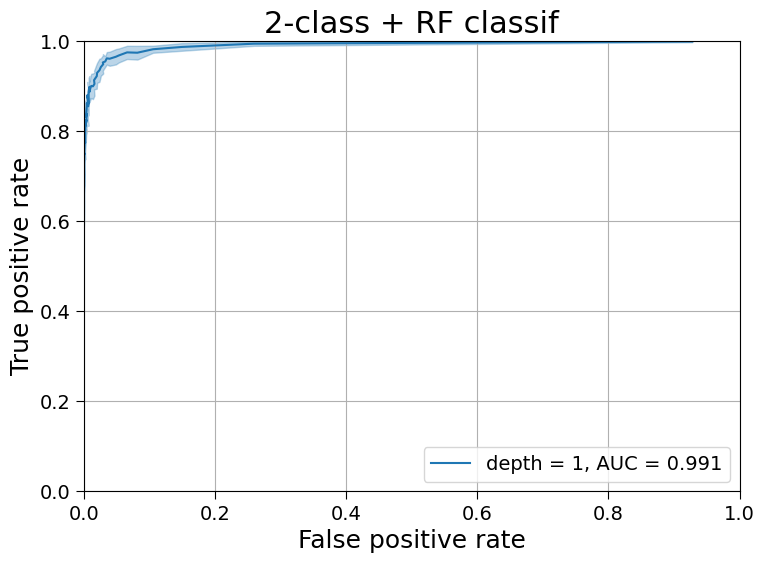

In [60]:
#fig_size =  [8, 6]
#pyplot.rcParams['figure.figsize'] =  fig_size
putil.setup_figure_pars(pars_dict=single_plot_pars)


nbins = 50
#nbins = 90
nbins_all = 20
nbins_rel = 5

pyplot.figure()
for level in range(level0, max_level):
    fprs = np.zeros((nav, nbins))
    tprs = np.zeros((nav, nbins))
    nn = np.zeros((nav, nbins))
    auc_av = 0.

    for j in range(nav):
        y_score = pred_dict_all[j][class1][level]['y_pred']
        y_true = pred_dict_all[j][class1][level]['y_true']
        weights = pred_dict_all[j]['test_weights']
        fpr, tpr, thres = roc_curve(y_true, y_score, sample_weight=weights)
        auc = roc_auc_score(y_true, y_score, sample_weight=weights)
        auc_av += auc / nav

        fprb, thresc, mask = make_thres_bins(thres, fpr, nbins=nbins)
        tprb, thresc, mask = make_thres_bins(thres, tpr, nbins=nbins)
        fprs[j][mask] = fprb
        tprs[j][mask] = tprb
        nn[j] = mask.astype(float)

    mask = (nn > 0)
    # keep columns with two or more entries for all j
    mask_av = (np.sum(nn, axis=0) > 1)
    fprs = fprs[:, mask_av]
    tprs = tprs[:, mask_av]
    mask = mask[:, mask_av]

    # average over elements with non-zero number of entries
    fpr_av = np.mean(fprs, axis=0, where=mask)
    fpr_std = np.std(fprs, axis=0, where=mask)
    tpr_av = np.mean(tprs, axis=0, where=mask)
    tpr_std = np.std(tprs, axis=0, where=mask)


    #pyplot.plot(fpr, tpr, label='depth = %s, AUC = %.3f' % (level+1, auc))
    if level == level0:
        ls = '-'
    else:
        ls = '--'
    pl = pyplot.plot(fpr_av, tpr_av, ls=ls, color=colors[level],
                     label='depth = %s, AUC = %.3f' % (level+1, auc_av))
    
    if level == level0:
        color = pl[0].get_color()
        pyplot.fill_between(fpr_av, tpr_av - tpr_std, tpr_av + tpr_std, 
                            alpha=0.3, color=color)

    pyplot.xlim(0.0, 1)
    pyplot.ylim(0.0, 1)
    #pyplot.legend(loc='lower right', fontsize=12, labelspacing=0.1)
    pyplot.legend(loc='lower right')
    pyplot.xlabel('False positive rate')
    pyplot.ylabel('True positive rate')
    title = title_str
    if purpose == 'DFG':
        pyplot.title('Receiver operating characteristic')
    else:
        pyplot.title(title)
    if not save_plots:
        pyplot.grid()
if save_plots:
    fn = '%sROC_%s.pdf' % (plots_folder, alg_descr)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        pyplot.savefig(fn.replace('.pdf', '.png'), metadata=fig_meta)
    if copy2tex and 0:
        plots_folder_paper = paper_folder + 'plots/performance/'
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



# ROC curves

plot
[0.9912115297105368, 0.9912115297105368]
auc_scan
0.0


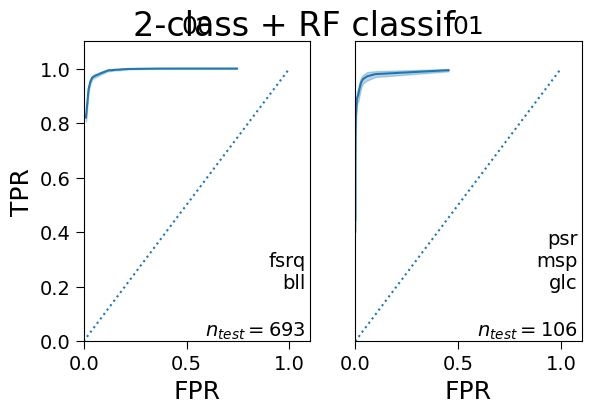

In [61]:
ncols = len(horiz_trees[max_level - 1])
nrows = max_level - level0
xtext_pos = 1.08

fig_height = 2 * nrows + 2   # height in inches
fig_width = 2 * ncols + 2  # width in inches

fig_size =  [fig_width, fig_height]
all_plots_pars['fig_size'] = fig_size
putil.setup_figure_pars(pars_dict=all_plots_pars)
res_dict = {} # save ROC results

pyplot.figure()
for level, subtree in enumerate(horiz_trees[level0:max_level]):
    #print(level)
    cut_subtree = util.sub_tree2tree_cat_dict(subtree, cat_tree, tree_cat_dict, 
                                              include_parents=True)
    nodes = subtree #list(cut_subtree.keys())

    xshift = 0
    for i, node in enumerate(nodes):
        res_dict[node] = {}
        res_dict[node]['classes'] = cut_subtree[node]
        nsrc = np.sum([nsrc_dict[cl] for cl in cut_subtree[node]])
        ind = level * ncols + xshift + 1
        ax = pyplot.subplot(nrows, ncols, ind)
        if level < max_level - 1:
            xshift += len(util.get_subtree(node, horiz_trees[max_level - 1]))
        else:
            xshift += 1
        
        # calculate TPR and FPR -> ROC for the node itself and for lower levels
        #xs = rel_dict[level][node]['prob_pred']
        #ys = rel_dict[level][node]['prob_true']
        #err = rel_dict[level][node]['err_true']
        for level_down in range(level, max_level)[::-1]:
            res_dict[node][level_down] = {}
            #y_score = pred_dict_all[node][level_down]['y_pred']
            #y_true = pred_dict_all[node][level_down]['y_true']
            #fpr, tpr, thres = roc_curve(y_true, y_score)
            #auc = roc_auc_score(y_true, y_score)
            #pyplot.plot(fpr, tpr, label='%s (%.3f)' % (level_down+1, auc))
            fprs = np.zeros((nav, nbins_all))
            tprs = np.zeros((nav, nbins_all))
            nn = np.zeros((nav, nbins_all))
            auc_av = 0.

            for j in range(nav):
                y_score = pred_dict_all[j][node][level_down]['y_pred']
                y_true = pred_dict_all[j][node][level_down]['y_true']
                weights = pred_dict_all[j]['test_weights']
                fpr, tpr, thres = roc_curve(y_true, y_score, sample_weight=weights)
                auc = roc_auc_score(y_true, y_score, sample_weight=weights)
                auc_av += auc / nav

                fprb, thresc, mask = make_thres_bins(thres, fpr, nbins=nbins_all)
                tprb, thresc, mask = make_thres_bins(thres, tpr, nbins=nbins_all)
                fprs[j][mask] = fprb
                tprs[j][mask] = tprb
                nn[j] = mask.astype(float)

            mask = (nn > 0)
            # keep columns with two or more entries for all j
            mask_av = (np.sum(nn, axis=0) > 1)
            fprs = fprs[:, mask_av]
            tprs = tprs[:, mask_av]
            mask = mask[:, mask_av]
            
            # average over elements with non-zero number of entries
            fpr_av = np.mean(fprs, axis=0, where=mask)
            fpr_std = np.std(fprs, axis=0, where=mask)
            tpr_av = np.mean(tprs, axis=0, where=mask)
            tpr_std = np.std(tprs, axis=0, where=mask)

            res_dict[node][level_down]['FPR'] = fpr_av
            res_dict[node][level_down]['TPR'] = tpr_av
            res_dict[node][level_down]['AUC'] = auc_av
            pl = pyplot.plot(fpr_av, tpr_av, color=colors[level_down],
                             label='%s (%.3f)' % (level_down+1, auc_av))
            
            
            
            if level_down == level:
                res_dict[node][level_down]['TPR_STD'] = tpr_std
                color = pl[0].get_color()
                pyplot.fill_between(fpr_av, tpr_av - tpr_std, tpr_av + tpr_std, 
                                    alpha=0.3, color=color)

        
        #pyplot.errorbar(xs, ys, yerr=err, marker='s', ls='')
        pyplot.plot([0,1], [0,1], ls=':')
        
        
        if i == 0:
            pyplot.ylabel('TPR')
        else:
            ax.axes.yaxis.set_visible(False)
        if level == max_level - 1:
            pyplot.xlabel('FPR')
            text = ''
            for i, cls in enumerate(cut_subtree[node]):
                text = ''
                for i, cls in enumerate(cut_subtree[node]):
                    text += cls
                    if len(cut_subtree[node]) < 5 or i % 2 != 0:
                        text += '\n'
                    else:
                        text += ' '
            ax.text(xtext_pos, 0.1, text, #fontsize=12, 
                    horizontalalignment='right', 
                    verticalalignment='bottom')
        else:
            ax.axes.xaxis.set_visible(False)
        ax.text(xtext_pos, 0.0, r'$n_{test} = %i$' % np.round(nsrc * test_frac), 
                #fontsize=12, 
                horizontalalignment='right', verticalalignment='bottom')
        #pyplot.title('Level %i, %s' % (level, cut_subtree[node]))
        # pyplot.title('Level %i, %s' % (level, node))
        pyplot.xlim(0, 1.1)
        pyplot.ylim(0, 1.1)
        #pyplot.legend()
        if tree_alg != '2class':
            pyplot.title('%s' % (node))
    if 1:
        print('plot')
        print([res_dict[node][level]['AUC'] for node in nodes])
        print('auc_scan')
        print(auc_scan[level])

if purpose == 'DFG':
    pyplot.suptitle('Receiver operating characteristics', size=24)
else:
    pyplot.suptitle(title_str, size=24)
if save_plots:
    fn = '%sROC_depth%i_%s.pdf' % (plots_folder, max_level, alg_descr)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png, metadata=fig_meta)
    if copy2tex and case == '4FGL-DR4_GMM_RF_w':
        plots_folder_paper = paper_folder + 'plots/performance/'
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



In [62]:
if save_results:
    roc_fn = results_folder + 'roc_dict.yaml'
    dio3.savedict(res_dict, roc_fn)

save dict to file:
../data_out/results_4FGL-DR4_no_bcu_spp_no_coord_features_2class_pulsars_AGNs_RF_depth15/roc_dict.yaml


# precision and recall

Depth 1, p = 0.500
Precision (purity) = 0.946 +- 0.017
Recall (efficiency) = 0.861 +- 0.025
save figure to file: ../plots/mclass/4FGL-DR4_no_bcu_spp_no_coord_features_2class_pulsars_AGNs_RF_depth15/prec_recall_4FGL-DR4_no_bcu_spp_no_coord_features_2class_pulsars_AGNs_RF_depth15.pdf


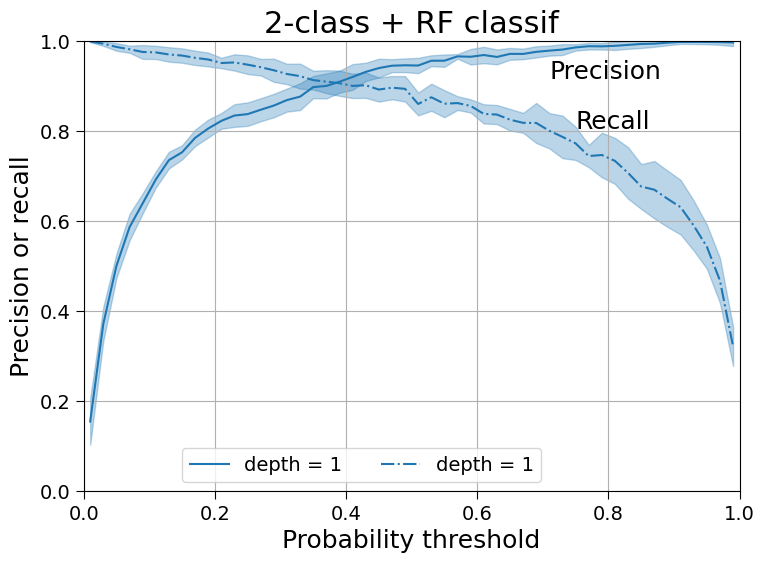

In [63]:
#fig_size =  [8, 6]
#pyplot.rcParams['figure.figsize'] =  fig_size
putil.setup_figure_pars(pars_dict=single_plot_pars)

#j = 0
node = class1
prec_av = {}
prec_std = {}
recall_av = {}
recall_std = {}
threscp = {}
threscr = {}

pshow = 0.501

fig = pyplot.figure()
for level in range(level0, max_level):
    #y_score = pred_dict_all[j][class1][level]['y_pred']
    #y_true = pred_dict_all[j][class1][level]['y_true']
    #prec, recall, thres = precision_recall_curve(y_true, y_score)
    #pyplot.plot(thres, prec[:-1], label='depth = %s (prec)' % (level+1))

    precs = np.zeros((nav, nbins))
    recalls = np.zeros((nav, nbins))
    nnp = np.zeros((nav, nbins))
    nnr = np.zeros((nav, nbins))

    for j in range(nav):
        y_score = pred_dict_all[j][node][level]['y_pred']
        y_true = pred_dict_all[j][node][level]['y_true']
        weights = pred_dict_all[j]['test_weights']
        prec, recall, thres = precision_recall_curve(y_true, y_score, sample_weight=weights)
        #print(prec.shape, thres.shape)

        precb, threscp_, maskp = make_thres_bins(thres, prec[:-1], nbins=nbins)
        recallb, threscr_, maskr = make_thres_bins(thres, recall[:-1], nbins=nbins)
        precs[j][maskp] = precb
        recalls[j][maskr] = recallb
        nnp[j] = maskp.astype(float)
        nnr[j] = maskr.astype(float)

    maskp = (nnp > 0)
    # keep columns with two or more entries for all j
    mask_avp = (np.sum(nnp, axis=0) > 1)
    precs = precs[:, mask_avp]
    maskp = maskp[:, mask_avp]
    threscp[level] = threscp_[mask_avp]

    maskr = (nnr > 0)
    # keep columns with two or more entries for all j
    mask_avr = (np.sum(nnr, axis=0) > 1)
    recalls = recalls[:, mask_avr]
    maskr = maskr[:, mask_avr] 
    threscr[level] = threscr_[mask_avr]

    # average over elements with non-zero number of entries
    prec_av[level] = np.mean(precs, axis=0, where=maskp)
    prec_std[level] = np.std(precs, axis=0, where=maskp)
    recall_av[level] = np.mean(recalls, axis=0, where=maskr)
    recall_std[level] = np.std(recalls, axis=0, where=maskr)

for level in range(level0, max_level):
    #pl = pyplot.plot(threscp, prec_av)
    if level == level0:
        ls = '-'
    else:
        ls = '--'
    if 0:
        label = 'depth = %s (prec)' % (level+1)
    else:
        label = 'depth = %s' % (level+1)

    pl = pyplot.plot(threscp[level], prec_av[level], 
                     color=colors[level], ls=ls, label=label)
    if pshow is not None:
        ishow = np.argmin(np.abs(threscp[level] - pshow))
        pb = (threscp[level][ishow] + threscp[level][ishow - 1]) / 2.
        print('Depth %i, p = %.3f' % (level + 1, pb))
        print('Precision (purity) = %.3f +- %.3f' % (prec_av[level][ishow], prec_std[level][ishow]))



    if level == level0:
        color = pl[0].get_color()
        minv = prec_av[level] - prec_std[level]
        maxv = prec_av[level] + prec_std[level]
        pyplot.fill_between(threscp[level], minv, maxv, alpha=0.3, color=color)

for level in range(level0, max_level):
    #pl = pyplot.plot(threscr, recall_av, ls='--')
    if level == level0:
        ls = '-.'
    else:
        ls = ':'
    if 0:
        label = 'depth = %s (recall)' % (level+1)
    else:
        label = 'depth = %s' % (level+1)
    pl = pyplot.plot(threscr[level], recall_av[level], 
                     color=colors[level], ls=ls, label=label)
    
    if pshow is not None:
        ishow = np.argmin(np.abs(threscr[level] - pshow))
        pb = (threscp[level][ishow] + threscp[level][ishow - 1]) / 2.
        print('Recall (efficiency) = %.3f +- %.3f' % (recall_av[level][ishow], recall_std[level][ishow]))

    if level == level0:
        color = pl[0].get_color()
        minv = recall_av[level] - recall_std[level]
        maxv = recall_av[level] + recall_std[level]
        pyplot.fill_between(threscr[level], minv, maxv, alpha=0.3, color=color)

#for level in pred_dict.keys():
    #y_score = pred_dict_all[class1][level]['y_pred']
    #y_true = pred_dict_all[class1][level]['y_true']
    #prec, recall, thres = precision_recall_curve(y_true, y_score)
    #pyplot.plot(thres, recall[:-1], ls='--', label='depth = %s (recall)' % (level+1))

pyplot.xlim(0.0, 1)
pyplot.ylim(0.0, 1)
#pyplot.legend(loc='lower left', ncol=2, fontsize=12, labelspacing=0.1)
if tree_alg != '2class':
    pyplot.legend(loc=(0.15, 0.02), ncol=2)
pyplot.xlabel('Probability threshold')
pyplot.ylabel('Precision or recall')
ax = fig.axes[0]
if tree_alg == '4class':
    ind = int(0.1 * nbins)
    xpos = threscr[0][ind] + 0.01
    ypos = prec_av[0][ind]
    ax.text(xpos, ypos, 'Precision', fontsize=18, horizontalalignment='left', 
                        verticalalignment='top')
    ind = int(0.8 * nbins)
    xpos = threscr[0][ind] - 0.03
    ypos = recall_av[0][ind] - 0.02
    ax.text(xpos, ypos, 'Recall', fontsize=18, horizontalalignment='right', 
                        verticalalignment='top')
else:
    ind = int(0.7 * nbins)
    xpos = threscr[0][ind]
    ypos = prec_av[0][ind] - 0.02
    ax.text(xpos, ypos, 'Precision', fontsize=18, horizontalalignment='left', 
                        verticalalignment='top')
    ind = int(0.75 * nbins)
    xpos = threscr[0][ind]
    ypos = recall_av[0][ind] + 0.02
    ax.text(xpos, ypos, 'Recall', fontsize=18, horizontalalignment='left', 
                        verticalalignment='bottom')

if add_low_p:
    prec, recall, thres = precision_recall_curve(y_true_check, y_pred_check, sample_weight=sample_ratio_check)
    #print(prec.shape, thres.shape)

    precb, thresc, maskp = make_thres_bins(thres, prec[:-1], nbins=nbins)
    recallb, thresc, maskr = make_thres_bins(thres, recall[:-1], nbins=nbins)
    pyplot.plot(thresc[maskp], precb, ls='--', label='')
    pyplot.plot(thresc[maskr], recallb, ls=':', label='')


if purpose == 'DFG':
    pyplot.title('Precision and recall')
elif tree_alg == '4class' or tree_alg == '2class':
    if class1 == '01':
        pyplot.title('Galactic')
    elif class1 == '00':
        pyplot.title('Extragalactic')
else:
    pyplot.title(title_str)
if not save_plots:
    pyplot.grid()
save_plots = 1
save_png = 1
if save_plots:
    fn = '%sprec_recall_%s.pdf' % (plots_folder, alg_descr)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png, metadata=fig_meta)
    if copy2tex and 0:
        plots_folder_paper = paper_folder + 'plots/performance/'
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)


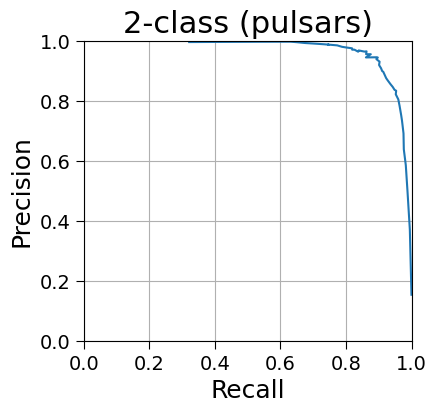

In [71]:
if case == '4FGL-DR4_2class_pulsars_AGNs':
    pyplot.figure(figsize=(4, 4))
    pyplot.plot(recall_av[0], prec_av[0])
    pyplot.title('2-class (pulsars)')
    pyplot.xlabel('Recall')
    pyplot.ylabel('Precision')
    pyplot.xlim(0, 1)
    pyplot.ylim(0, 1)
    pyplot.grid()

In [30]:
len(thres)

40

In [31]:
#sum(y_true_check), sum(y_pred_check), len(y_true_check)

In [32]:
sum(np.sum(nnr, axis=0) > 0)

50

In [33]:
class1

'01'

save figure to file: ../plots/mclass/4FGL-DR4_no_bcu_spp_no_coord_features_2class_pulsars_AGNs_RF_depth15/prec_recall_depth1_4FGL-DR4_no_bcu_spp_no_coord_features_2class_pulsars_AGNs_RF_depth15.pdf


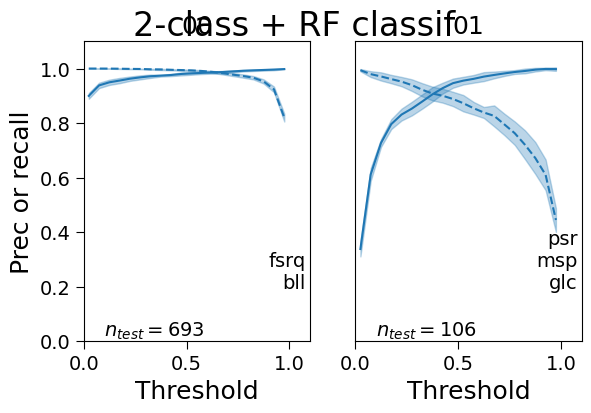

In [79]:
res_dict = {} # save precition and recall results


ncols = len(horiz_trees[max_level - 1])
nrows = max_level - level0

fig_height = 2 * nrows + 2   # height in inches
fig_width = 2 * ncols + 2  # width in inches

fig_size =  [fig_width, fig_height]
all_plots_pars['fig_size'] = fig_size
putil.setup_figure_pars(pars_dict=all_plots_pars)


pyplot.figure()
for level, subtree in enumerate(horiz_trees[level0:max_level]):
#for level in range(max_level - 1, level0 - 1, -1):
#    subtree = horiz_trees[level]
    #print(level)
    cut_subtree = util.sub_tree2tree_cat_dict(subtree, cat_tree, tree_cat_dict, 
                                              include_parents=True)
    nodes = subtree #list(cut_subtree.keys())

    xshift = 0
    for i, node in enumerate(nodes):
        res_dict[node] = {}
        res_dict[node]['classes'] = cut_subtree[node]

        nsrc = np.sum([nsrc_dict[cl] for cl in cut_subtree[node]])
        ind = level * ncols + xshift + 1
        ax = pyplot.subplot(nrows, ncols, ind)
        if level < max_level - 1:
            xshift += len(util.get_subtree(node, horiz_trees[max_level - 1]))
        else:
            xshift += 1
        
        # calculate TPR and FPR -> ROC for the node itself and for lower levels
        #xs = rel_dict[level][node]['prob_pred']
        #ys = rel_dict[level][node]['prob_true']
        #err = rel_dict[level][node]['err_true']
        for level_down in range(level, max_level)[::-1]:
            res_dict[node][level_down] = {}
            #y_score = pred_dict_all[node][level_down]['y_pred']
            #y_true = pred_dict_all[node][level_down]['y_true']
            #prec, recall, thres = precision_recall_curve(y_true, y_score)
            #pyplot.plot(thres, prec[:-1])
            #pyplot.plot(thres, recall[:-1], ls='--')
            
            precs = np.zeros((nav, nbins_all))
            recalls = np.zeros((nav, nbins_all))
            nnp = np.zeros((nav, nbins_all))
            nnr = np.zeros((nav, nbins_all))

            for j in range(nav):
                y_score = pred_dict_all[j][node][level_down]['y_pred']
                y_true = pred_dict_all[j][node][level_down]['y_true']
                weights = pred_dict_all[j]['test_weights']
                prec, recall, thres = precision_recall_curve(y_true, y_score, sample_weight=weights)
                #print(prec.shape, thres.shape)

                precb, thresc, maskp = make_thres_bins(thres, prec[:-1], nbins=nbins_all)
                recallb, thresc, maskr = make_thres_bins(thres, recall[:-1], nbins=nbins_all)
                precs[j][maskp] = precb
                recalls[j][maskr] = recallb
                nnp[j] = maskp.astype(float)
                nnr[j] = maskr.astype(float)

            maskp = (nnp > 0)
            # keep columns with two or more entries for all j
            mask_avp = (np.sum(nnp, axis=0) > 1)
            precs = precs[:, mask_avp]
            maskp = maskp[:, mask_avp]
            threscp = thresc[mask_avp]

            maskr = (nnr > 0)
            # keep columns with two or more entries for all j
            mask_avr = (np.sum(nnr, axis=0) > 1)
            recalls = recalls[:, mask_avr]
            maskr = maskr[:, mask_avr] 
            threscr = thresc[mask_avr]

            # average over elements with non-zero number of entries
            prec_mean = np.mean(precs, axis=0, where=maskp)
            prec_std = np.std(precs, axis=0, where=maskp)
            recall_mean = np.mean(recalls, axis=0, where=maskr)
            recall_std = np.std(recalls, axis=0, where=maskr)

            
            pl = pyplot.plot(threscp, prec_mean, color=colors[level_down])
            
            if level_down == level:
                color = pl[0].get_color()
                pyplot.fill_between(threscp, prec_mean - prec_std, prec_mean + prec_std, 
                                    alpha=0.3, color=color)

            pl = pyplot.plot(threscr, recall_mean, 
                             color=colors[level_down], ls='--')

            if level_down == level:
                color = pl[0].get_color()
                pyplot.fill_between(threscr, recall_mean - recall_std, recall_mean + recall_std, 
                                    alpha=0.3, color=color)
                
            res_dict[node][level_down]['thres_prec'] = threscp
            res_dict[node][level_down]['prec'] = prec_mean
            res_dict[node][level_down]['thres_recall'] = threscr
            res_dict[node][level_down]['recall'] = recall_mean
            if level_down == level:
                res_dict[node][level_down]['prec_std'] = prec_std
                res_dict[node][level_down]['recall_std'] = recall_std
                
        if i == 0:
            pyplot.ylabel('Prec or recall')
        else:
            ax.axes.yaxis.set_visible(False)
        if level == max_level - 1:
            pyplot.xlabel('Threshold')
            text = ''
            for i, cls in enumerate(cut_subtree[node]):
                text = ''
                for i, cls in enumerate(cut_subtree[node]):
                    text += cls
                    if len(cut_subtree[node]) < 5 or i % 2 != 0:
                        text += '\n'
                    else:
                        text += ' '
            if tree_alg == '4class':
                ax.text(0.1, 0.1, text, #fontsize=12, 
                        horizontalalignment='left', 
                        verticalalignment='bottom')
            else:
                ax.text(xtext_pos, 0.1, text, #fontsize=12, 
                        horizontalalignment='right', 
                        verticalalignment='bottom')
        else:
            ax.axes.xaxis.set_visible(False)
        ax.text(0.1, 0.0, r'$n_{test} = %i$' % np.round(nsrc * test_frac), 
                #fontsize=12, 
                horizontalalignment='left', verticalalignment='bottom')
        #pyplot.title('Level %i, %s' % (level, cut_subtree[node]))
        # pyplot.title('Level %i, %s' % (level, node))
        pyplot.xlim(0, 1.1)
        pyplot.ylim(0, 1.1)
        #pyplot.legend()
        if tree_alg != '2class':
            pyplot.title('%s' % (node))
if purpose == 'DFG':
    pyplot.suptitle('Precision and recall', size=24)
else:
    pyplot.suptitle(title_str, size=24)
if save_plots:
    fn = '%sprec_recall_depth%i_%s.pdf' % (plots_folder, max_level, alg_descr)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png, metadata=fig_meta)
    if copy2tex and 0:
        plots_folder_paper = paper_folder + 'plots/performance/'
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



In [80]:
if save_results:
    pr_fn = results_folder + 'pr_dict.yaml'
    dio3.savedict(res_dict, pr_fn)

save dict to file:
../data_out/results_4FGL-DR4_no_bcu_spp_no_coord_features_2class_pulsars_AGNs_RF_depth15/pr_dict.yaml


In [83]:
if case == '4FGL-DR4_2class_pulsars_AGNs':
    res_dict_min = {}
    res_dict_min['Precision'] = res_dict['01'][0]['prec']
    res_dict_min['Recall'] = res_dict['01'][0]['recall']
    #print(res_dict_min)
    #print(recall_av)
    pr_fn_min = results_folder + 'pr_dict_pulsars_2class.yaml'
    dio3.savedict(res_dict_min, pr_fn_min)

save dict to file:
../data_out/results_4FGL-DR4_no_bcu_spp_no_coord_features_2class_pulsars_AGNs_RF_depth15/pr_dict_pulsars_2class.yaml


In [74]:
results_folder

'../data_out/results_4FGL-DR4_no_bcu_spp_no_coord_features_2class_pulsars_AGNs_RF_depth15/'

# reliability diagrams

In [608]:
if 0:
    j = 0
    node = '00000'
    print(pred_dict_all[j][node])
    level = 4
    y_score = pred_dict_all[j][node][level]['y_pred']
    y_true = pred_dict_all[j][node][level]['y_true']

    pt, pp = calibration_curve(y_true, y_score, n_bins=10)
    print(pt, pp)

In [609]:
all_plots_pars

{'bottom': 0.1,
 'left': 0.08,
 'right': 0.98,
 'axes.titlesize': 18,
 'font.size': 13,
 'fig_size': [12, 8]}

save figure to file: ../plots/mclass/4FGL-DR4_no_bcu_spp_no_coord_features_GMM_nmin80_RF_depth15_test_gal_plane_lon30_lat30_around_GC/reliability_diag_depth3_4FGL-DR4_no_bcu_spp_no_coord_features_GMM_nmin80_RF_depth15_test_gal_plane_lon30_lat30_around_GC.pdf


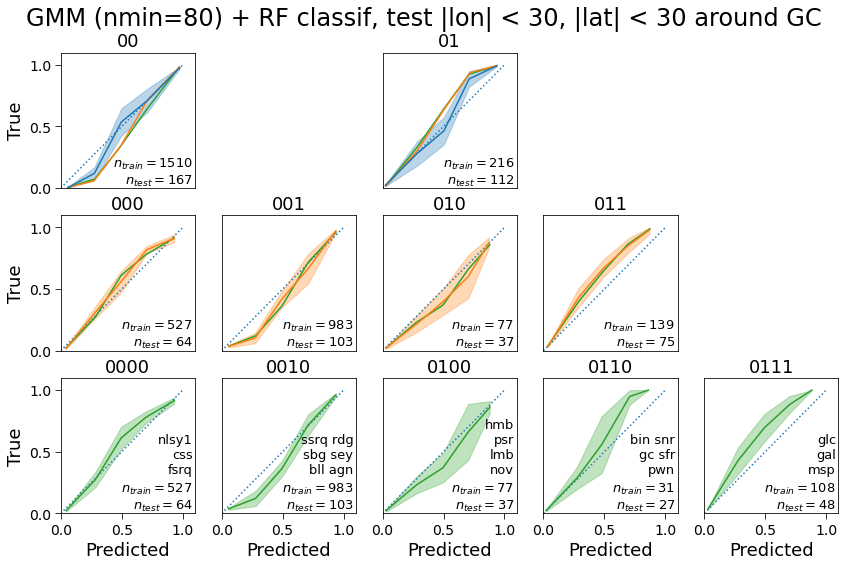

In [610]:
res_dict = {} # save calibration diagram results

ncols = len(horiz_trees[max_level - 1])
nrows = max_level - level0

fig_height = 2 * nrows + 2   # height in inches
fig_width = 2 * ncols + 2  # width in inches

fig_size =  [fig_width, fig_height]
#pyplot.rcParams['figure.figsize'] =  fig_size
#pyplot.rcParams['axes.titlesize'] =  18
all_plots_pars['fig_size'] = fig_size
putil.setup_figure_pars(pars_dict=all_plots_pars)

thres = 1.e-10

pyplot.figure()
for level, subtree in enumerate(horiz_trees[level0:max_level]):
    #print(level)
    cut_subtree = util.sub_tree2tree_cat_dict(subtree, cat_tree, tree_cat_dict, 
                                              include_parents=True)
    nodes = subtree #list(cut_subtree.keys())

    xshift = 0
    for i, node in enumerate(nodes):
        res_dict[node] = {}
        res_dict[node]['classes'] = cut_subtree[node]

        #print(node)
        nsrc = np.sum([nsrc_dict[cl] for cl in cut_subtree[node]])
        ind = level * ncols + xshift + 1
        ax = pyplot.subplot(nrows, ncols, ind)
        if level < max_level - 1:
            xshift += len(util.get_subtree(node, horiz_trees[max_level - 1]))
        else:
            xshift += 1
            
        if 0:
            xs = rel_dict[level][node]['prob_pred']
            ys = rel_dict[level][node]['prob_true']
            err = rel_dict[level][node]['err_true']
            pyplot.errorbar(xs, ys, yerr=err, marker='s', ls='')
        else:
            pyplot.plot([0,1], [0,1], ls=':')
            for level_down in range(level, max_level)[::-1]:
                res_dict[node][level_down] = {}
                pts = np.zeros((nav, nbins_rel))
                pps = np.zeros((nav, nbins_rel))
                nn = np.zeros((nav, nbins_rel))

                for j in range(nav):
                    y_score = pred_dict_all[j][node][level_down]['y_pred']
                    y_score = np.minimum(y_score, 1.)
                    y_true = pred_dict_all[j][node][level_down]['y_true']
                    weights = pred_dict_all[j]['test_weights']

                    #pt, pp = calibration_curve(y_true, y_score, n_bins=nbins_rel)
                    pt, pp = calibration_curve_loc(y_true, y_score, n_bins=nbins_rel, sample_weight=weights)
                    #pts[j][:len(pt)] = pt
                    #pps[j][:len(pp)] = pp
                    #nn[j][:len(pp)] = 1.
                    pts[j] = pt
                    pps[j] = pp
                    nn[j] = (pp > thres).astype(float)
                    
                
                mask = nn.astype(bool)
                # keep columns with two or more entries for all j
                mask_av = (np.sum(nn, axis=0) > 1)
                pts = pts[:, mask_av]
                pps = pps[:, mask_av]
                mask = mask[:, mask_av]

                # average over elements with non-zero number of entries
                pt_av = np.mean(pts, axis=0, where=mask)
                pt_std = np.std(pts, axis=0, where=mask)
                pp_av = np.mean(pps, axis=0, where=mask)
                pp_std = np.std(pps, axis=0, where=mask)
                if node == '0100' and False:
                    print('predict')
                    print(pps)
                    print(mask)
                    print(pp_av)
                    print(pp_std)
                    print('true')
                    print(pt_av)
                    print(pt_std)


                pl = pyplot.plot(pp_av, pt_av, color=colors[level_down])

                if level_down == level:
                    color = pl[0].get_color()
                    minv = np.maximum(0., pt_av - pt_std)
                    maxv = np.minimum(1., pt_av + pt_std)                    
                    pyplot.fill_between(pp_av, minv, maxv, 
                                        alpha=0.3, color=color)
                    
                res_dict[node][level_down]['predicted'] = pp_av
                res_dict[node][level_down]['true'] = pt_av
                if level_down == level:
                    res_dict[node][level_down]['true_min'] = minv
                    res_dict[node][level_down]['true_max'] = maxv
                    res_dict[node][level_down]['predicted_std'] = pp_std
                    res_dict[node][level_down]['true_std'] = pt_std


        if i == 0:
            pyplot.ylabel('True')
        else:
            ax.axes.yaxis.set_visible(False)
        if level == max_level - 1:
            pyplot.xlabel('Predicted')
            text = ''
            for i, cls in enumerate(cut_subtree[node]):
                text += cls
                if len(cut_subtree[node]) < 5 or i % 2 != 0:
                    text += '\n'
                else:
                    text += ' '
            if test_gal_plane:
                ypos_group = 0.3
            else:
                ypos_group = 0.1
            ax.text(xtext_pos, ypos_group, text[:-1], #fontsize=12, 
                    horizontalalignment='right', 
                    verticalalignment='bottom')
        else:
            ax.axes.xaxis.set_visible(False)
        if test_gal_plane:
            txt = r'$n_{train} = %i$' % gal_plane_nsrc_dict[level][node]['ntrain']
            txt += '\n'
            txt += r'$n_{test} = %i$' % gal_plane_nsrc_dict[level][node]['ntest']
            ax.text(xtext_pos, 0.0, txt,                    
                    #fontsize=12, 
                    horizontalalignment='right', verticalalignment='bottom')
            
        else:
            ax.text(xtext_pos, 0.0, r'$n_{test} = %i$' % np.round(nsrc * test_frac), 
                    #fontsize=12, 
                    horizontalalignment='right', verticalalignment='bottom')
        #pyplot.title('Level %i, %s' % (level, cut_subtree[node]))
        # pyplot.title('Level %i, %s' % (level, node))
        pyplot.xlim(0, 1.1)
        pyplot.ylim(0, 1.1)
        if tree_alg != '2class':
            pyplot.title('%s' % (node))
if purpose == 'DFG':
    pyplot.suptitle('Reliability diagrams', size=24)
else:
    pyplot.suptitle(title_str, size=24)
if save_plots:
    fn = '%sreliability_diag_depth%i_%s.pdf' % \
                (plots_folder, max_level, alg_descr)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png, metadata=fig_meta)
    if copy2tex and 0:
        plots_folder_paper = paper_folder + 'plots/performance/'
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



In [611]:
gal_plane_nsrc_dict[level][node]

{'ntrain': 108, 'ntest': 48}

In [612]:
if save_results:
    cal_fn = results_folder + 'cal_dict.yaml'
    dio3.savedict(res_dict, cal_fn)

save dict to file:
../data_out/results_4FGL-DR4_no_bcu_spp_no_coord_features_GMM_nmin80_RF_depth15_test_gal_plane_lon30_lat30_around_GC/cal_dict.yaml


In [613]:
clfs_dict.keys()

dict_keys([0, 1, 2])

In [614]:
level_viz = 0
clf = clfs_dict[level_viz]

In [615]:
#pd.DataFrame?
#importlib.reload(util);
#results_folder

In [616]:
fimp_folder = '../data_out/feature_importance/'
if not os.path.isdir(fimp_folder):
    os.mkdir(fimp_folder)

fimp_fn = fimp_folder + 'feature_importance.txt'
fimp_df_fn = fimp_folder + 'feature_importance.csv'
rewrite_fimp = True
save_fimp = False

if os.path.isfile(fimp_df_fn) and not rewrite_fimp:
    dffs = pd.read_csv(fimp_df_fn, index_col=0)
else:
    level = 0
    clm_name = 'Depth %i' % (level + 1)
    dffs = util.get_feature_importances(clfs_dict[level], clm_name=clm_name)
    for level in range(1, len(clfs_dict)):
        clm_name = 'Depth %i' % (level + 1)
        dffs_loc = util.get_feature_importances(clfs_dict[level], clm_name=clm_name)
        dffs[clm_name] = dffs_loc[clm_name]
    dffs = dffs.sort_values(clm_name, ascending=False)
    if save_fimp:
        dffs.to_csv(fimp_df_fn)
        
#if save_results and 
if dffs is not None and save_fimp:
    txt = util.df2tex(dffs, fmt='%.3f', index=True, index_name='')
    txt = txt.replace('_', '\_')
    fl = open(fimp_fn, 'w')
    fl.write(txt)
    fl.close()
    #dffs.to_csv(df_fn)

In [617]:
dffs

,Depth 1,Depth 2,Depth 3
LP_index1000MeV,0.036608,0.325779,0.337569
log10(Variability_Index),0.132007,0.146992,0.143918
LP_beta,0.305261,0.139700,0.142304
log10(Unc_Energy_Flux100),0.186058,0.121149,0.118720
LP_SigCurv,0.174133,0.107393,0.110863
log10(Energy_Flux100),0.096952,0.077223,0.074131
log10(Signif_Avg),0.068981,0.081763,0.072494


In [618]:
#print(txt)

In [619]:
horiz_trees

[['00', '01'],
 ['000', '001', '010', '011'],
 ['0000', '0010', '0100', '0110', '0111']]

In [620]:
tree_cat_dict

{'000': ['nlsy1', 'css', 'fsrq'],
 '001': ['ssrq', 'rdg', 'sbg', 'sey', 'bll', 'agn'],
 '010': ['hmb', 'psr', 'lmb', 'nov'],
 '0110': ['bin', 'snr', 'gc', 'sfr', 'pwn'],
 '0111': ['glc', 'gal', 'msp']}

In [621]:
cut_subtree = util.sub_tree2tree_cat_dict(horiz_trees[level_viz], cat_tree, tree_cat_dict, 
                                         include_parents=True)
print(cut_subtree)
if 1:
    cl_colors = {}
    cl_colors[0] = [[0., t, 0.6] for t in np.linspace(0.7, 0.3, 2)]
    cl_colors[1] = [[0.9, t, 0.] for t in np.linspace(0.7, 0.2, 2)]


    putil.setup_figure_pars(pars_dict=single_plot_pars)
    mrks = ['s', 'o', 'd', 'v']
    if level_viz == 0:
        cls_colors = {'00': cl_colors[0][0], '01':cl_colors[1][1],}
    elif level_viz == 1:
        cls_colors = {'000': cl_colors[0][0], '001':cl_colors[0][1], 
                      '010':cl_colors[1][0], '011':cl_colors[1][1]}
    f1 = dffs['Feature'].iloc[0] # 'LP_index1000MeV'
    f2 = dffs['Feature'].iloc[1] # 'Variability_Index'
    pyplot.figure()
    for i, key in enumerate(cut_subtree.keys()):
        cls = cut_subtree[key]
        cls_mask = util.get_cl_mask(cls, xdf, cname=class_name)

        x1 = xdf[f1][cls_mask]
        x2 = xdf[f2][cls_mask]
        label = cls[0]
        for cl in cls[1:]:
            label += ', %s' % cl
        #pyplot.plot(x1, x2, ls='', marker=mrks[i], ms=5, label=label)
        pyplot.plot(x1, x2, ls='', marker=mrks[i], ms=5, color=cls_colors[key], label=label)
    pyplot.legend(loc='best')
    #pyplot.xlabel('Spectral index at 1 GeV')
    #pyplot.ylabel('Log parabola beta')
    #pyplot.ylabel('log10(Variability index)')
    pyplot.xlabel(f1)
    pyplot.ylabel(f2)
    pyplot.title('%i-class classification features' % 2**(level_viz + 1))
    if save_plots:
        fn = '%s/split_tree_full_%s_depth%i.pdf' % (viz_plots_folder, alg_descr, (level_viz + 1))
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn, metadata=fig_meta)


{'00': ['nlsy1', 'css', 'fsrq', 'ssrq', 'rdg', 'sbg', 'sey', 'bll', 'agn'], '01': ['hmb', 'psr', 'lmb', 'nov', 'bin', 'snr', 'gc', 'sfr', 'pwn', 'glc', 'gal', 'msp']}


KeyError: 'Feature'

In [ ]:
cut_subtree

In [ ]:
cut_subtree.keys()

In [ ]:
4

In [ ]:
5

In [ ]:
sklearn.ensemble.RandomForestClassifier?